In [1]:
import sys
import torch
from pathlib import Path
from PIL import Image
from IPython.display import display

# 自动定位项目根目录
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "models/Xiaomi-Lens-0/infer.py").exists())

sys.path.insert(0, str(ROOT / "models/Xiaomi-Lens-0"))
sys.path.insert(0, str(ROOT / "models/Xiaomi-Lens-0/src"))

# 直接使用小米官方推理接口
from infer import (
    load_model_and_processor,
    build_inputs,
    generate_completion,
    run_forward,
    split_answer_content,
    parse_answer_bboxes,
    visualize_pixel_mask,
)

device = torch.device("cuda:0")
model, processor, mask_token_id = load_model_and_processor(
    "SeerRay-Lab/Xiaomi-Lens-0", device
)

/home/20261024_1/.local/share/mamba/envs/xiaomi-lens/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading checkpoint: SeerRay-Lab/Xiaomi-Lens-0


Loading weights: 100%|██████████| 749/749 [00:05<00:00, 137.83it/s]


<|mask|> token id: 248077


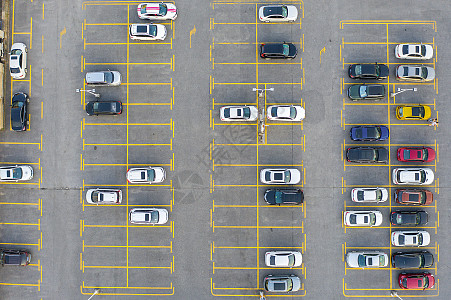

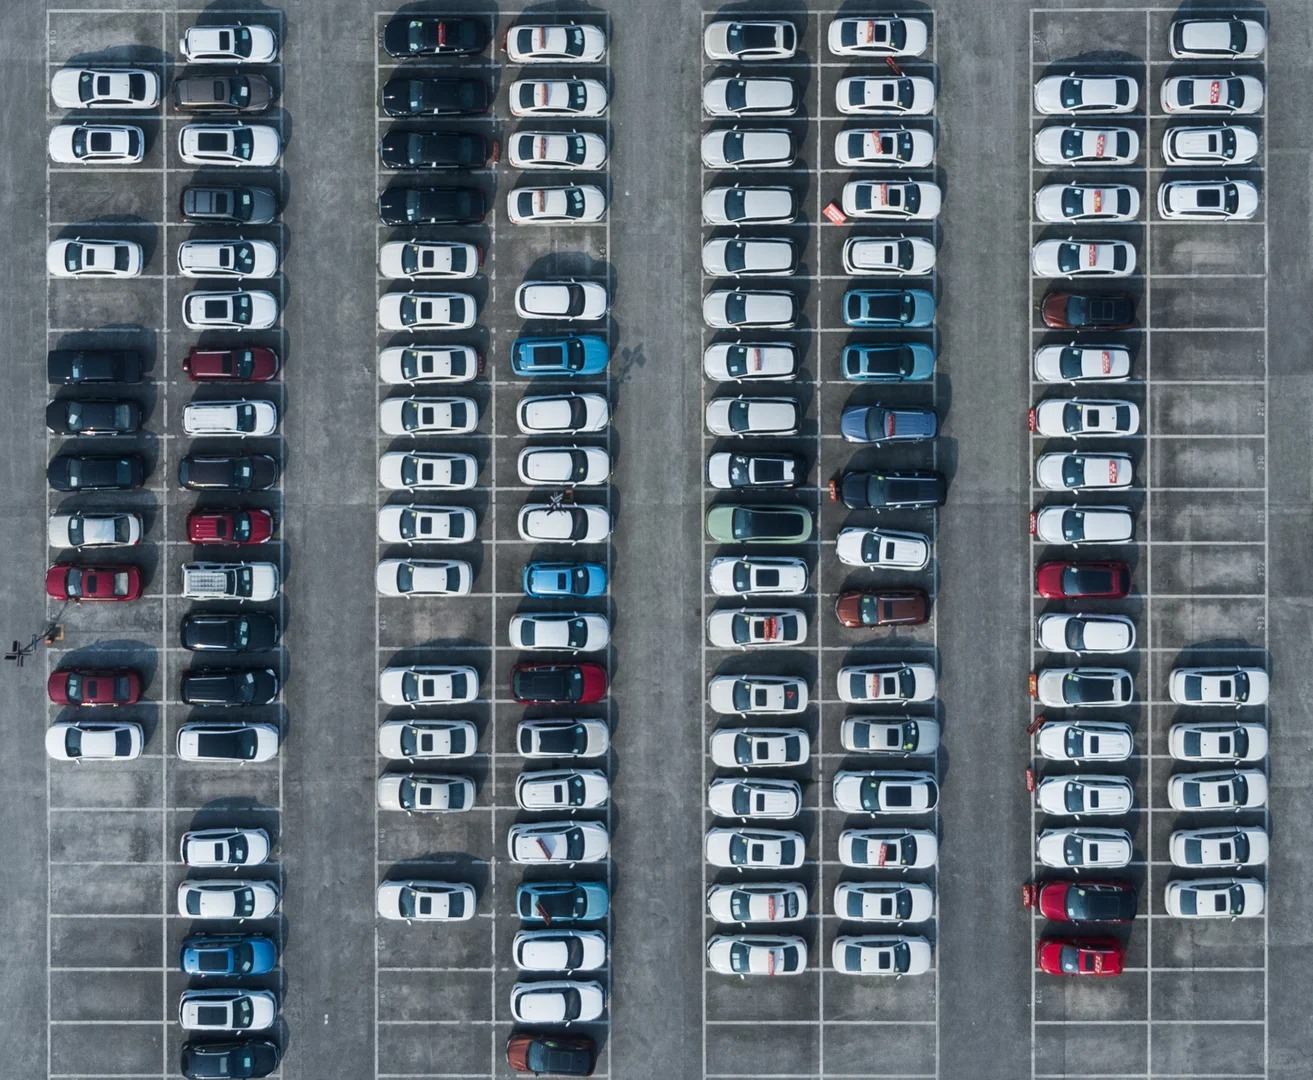

In [2]:
DATA_DIR = ROOT / "datasets/几何简单测试"

img1 = Image.open(DATA_DIR / "停车场图1.png").convert("RGB")
img2 = Image.open(DATA_DIR / "停车场图2.jpg").convert("RGB")

display(img1, img2)

In [3]:
def test(image, question, max_new_tokens=2048):
    # 1. 构造输入并生成回答
    inputs, _ = build_inputs(processor, image, question, device)

    ids, raw_text, num_masks = generate_completion(
        model, processor, inputs,
        max_new_tokens=max_new_tokens,
        mask_token_id=mask_token_id,
    )

    answer, thought_masks = split_answer_content(raw_text)
    boxes = parse_answer_bboxes(raw_text)

    # 2. 解码并绘制最终答案中的 Mask 和 BBox
    if num_masks > thought_masks:
        mask_logits = run_forward(model, inputs, ids, mask_token_id, device)
        mask_logits = mask_logits[:, thought_masks:]

        result = visualize_pixel_mask(
            image, mask_logits, inputs["image_grid_thw"],
            bboxes=boxes,
            draw_bbox=True,
            threshold=0.5,
        )
        display(result)
    else:
        print("模型未生成可视化 Mask")

    # 3. 输出最终回答（不显示 Thinking 内容）
    print("\n模型回答：")
    print(answer.strip())

### 一、单目标定位

`use_return_dict` is deprecated! Use `return_dict` instead!


Image grid: 18x28 raw patches; canvas 448x288px
K = 1 <|mask|> mask(s)
  mask[0] color=#ff4444 foreground=650/129024 (0.5%)
  bbox[0] normalized=[878, 896, 962, 967] -> px=(393,258,431,278)


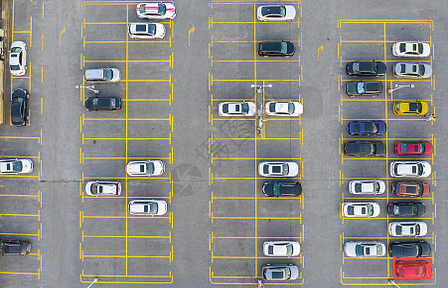


模型回答：
<bbox>[878, 896, 962, 967]</bbox><mask><|mask|></mask><|im_end|>


In [4]:
"""找到第一张图右下角的红色汽车，输出框和分割图。"""
question = """
Locate the red car at the bottom-right corner of the image.
Report its bounding box coordinates and segmentation mask.
"""

test(img1, question)

### 2.多目标定位

从结果看，貌似漏掉挺多的

Image grid: 68x82 raw patches; canvas 1312x1088px
K = 3 <|mask|> mask(s)
  mask[0] color=#ff4444 foreground=4061/1427456 (0.3%)
  mask[1] color=#44ff44 foreground=2737/1427456 (0.2%)
  mask[2] color=#4488ff foreground=4038/1427456 (0.3%)
  bbox[0] normalized=[389, 309, 465, 351] -> px=(510,336,610,382)
  bbox[1] normalized=[399, 518, 462, 552] -> px=(523,564,606,601)
  bbox[2] normalized=[136, 865, 212, 906] -> px=(178,941,278,986)


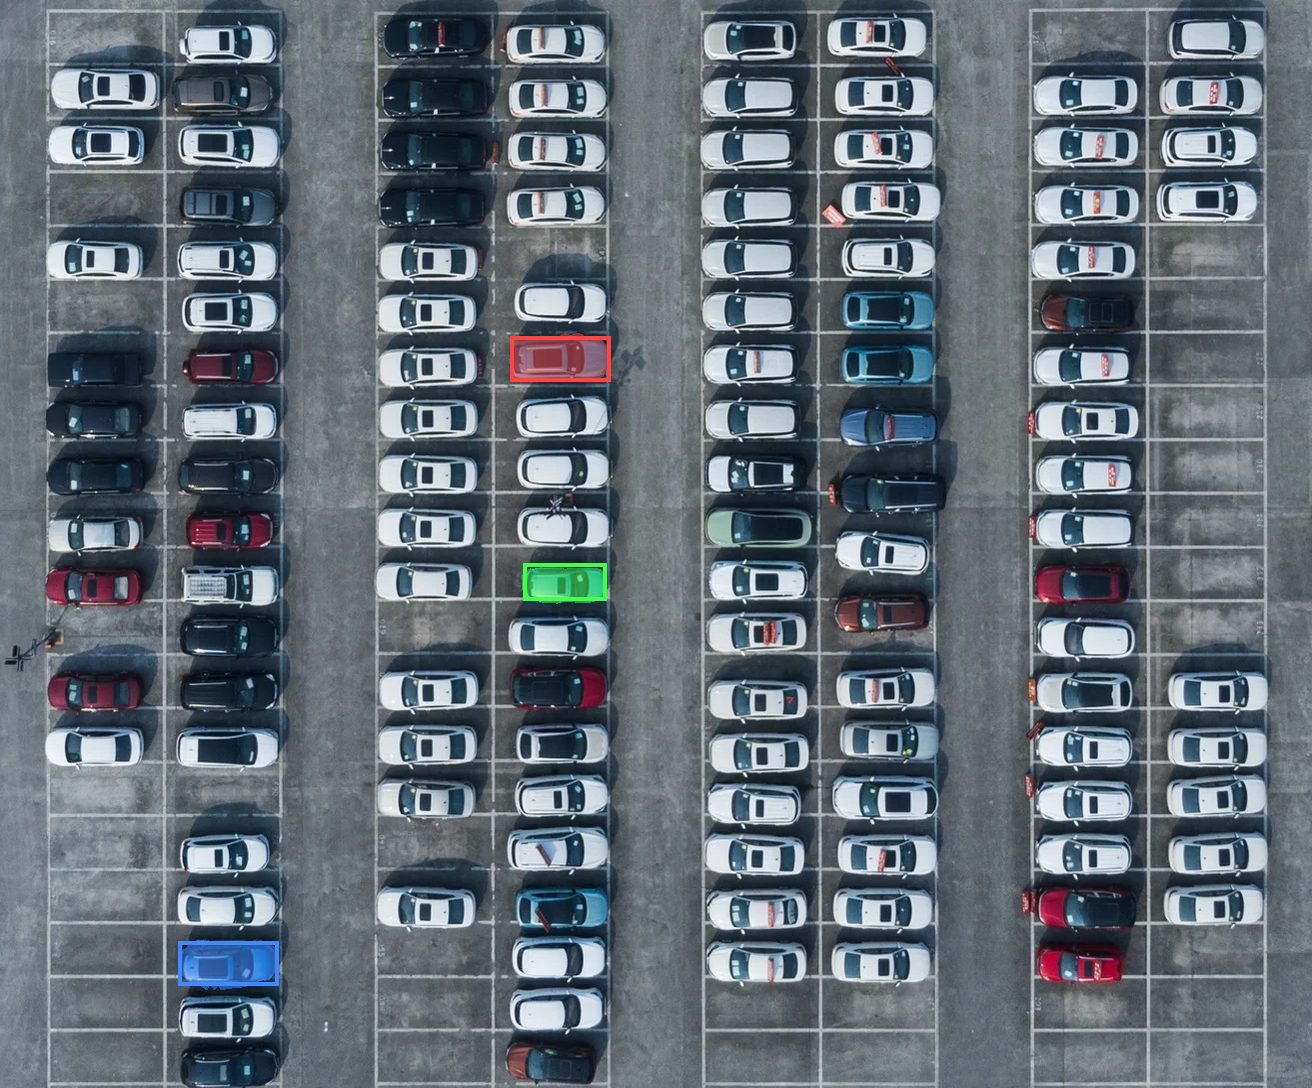


模型回答：
<bbox>[389, 309, 465, 351]</bbox><mask><|mask|></mask><bbox>[399, 518, 462, 552]</bbox><mask><|mask|></mask><bbox>[136, 865, 212, 906]</bbox><mask><|mask|></mask><|im_end|>


In [5]:
question = """
Locate all instances in the image that match the description "blue car".
For each instance, report its bounding box coordinates and mask.
"""

test(img2, question)

### 三、question = """
Find the blue car located lowest in the image.
Use image coordinates, not the real-world driving direction.

Report its bounding box and mask.
Then briefly describe its location in Chinese.
"""

test(img2, question)